In [15]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

In [2]:
adani = yf.download(
    "ADANIENT.NS",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True
)

print(adani.head())

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open      Volume
Ticker     ADANIENT.NS ADANIENT.NS ADANIENT.NS ADANIENT.NS ADANIENT.NS
Date                                                                  
2021-01-01  489.740936  491.834918  475.631537  475.631537     5035248
2021-01-04  493.081299  501.158066  485.253814  490.588471     4936582
2021-01-05  492.981537  499.961454  488.195320  490.588429     3654033
2021-01-06  489.491608  499.213635  482.860693  494.576982     3295461
2021-01-07  516.613525  522.446778  492.383255  492.482974     9879731


In [3]:
hul = yf.download(
    "HINDUNILVR.NS",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True
)

print(hul.head())

[*********************100%***********************]  1 of 1 completed

Price              Close          High           Low          Open  \
Ticker     HINDUNILVR.NS HINDUNILVR.NS HINDUNILVR.NS HINDUNILVR.NS   
Date                                                                 
2021-01-01   2173.496094   2188.471237   2168.443630   2180.642175   
2021-01-04   2208.953857   2212.140067   2185.466894   2189.381425   
2021-01-05   2230.847656   2236.673780   2189.381366   2189.381366   
2021-01-06   2200.578857   2230.347119   2186.286473   2226.523712   
2021-01-07   2156.472900   2214.598351   2152.967980   2213.961153   

Price             Volume  
Ticker     HINDUNILVR.NS  
Date                      
2021-01-01        830096  
2021-01-04       1614486  
2021-01-05       2356303  
2021-01-06       1641627  
2021-01-07       2403881  


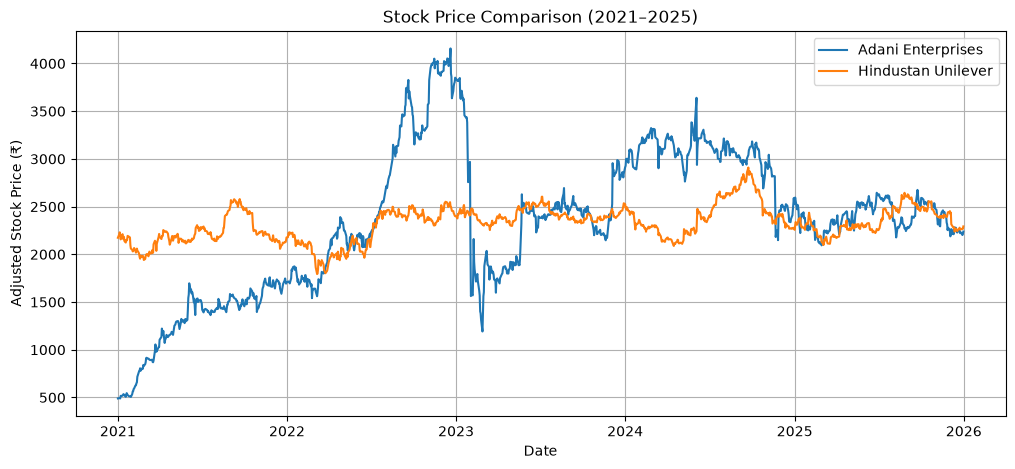

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(adani["Close"], label="Adani Enterprises")
plt.plot(hul["Close"], label="Hindustan Unilever")

plt.title("Stock Price Comparison (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Adjusted Stock Price (₹)")
plt.legend()
plt.grid(True)

plt.show()

In [7]:
# Calculate daily percentage returns
adani_returns = adani["Close"].pct_change().dropna()
hul_returns = hul["Close"].pct_change().dropna()

# Display the first five daily returns
print("Adani Enterprises daily returns:")
print(adani_returns.head())

print("\nHindustan Unilever daily returns:")
print(hul_returns.head())


Adani Enterprises daily returns:
Ticker      ADANIENT.NS
Date                   
2021-01-04     0.006821
2021-01-05    -0.000202
2021-01-06    -0.007079
2021-01-07     0.055408
2021-01-08    -0.000193

Hindustan Unilever daily returns:
Ticker      HINDUNILVR.NS
Date                     
2021-01-04       0.016314
2021-01-05       0.009911
2021-01-06      -0.013568
2021-01-07      -0.020043
2021-01-08       0.009435


In [10]:

# Black-Scholes: daily log returns
adani_log_returns = np.log(
    adani["Close"] / adani["Close"].shift(1)
).dropna()

hul_log_returns = np.log(
    hul["Close"] / hul["Close"].shift(1)
).dropna()

# Bachelier: daily absolute price changes in rupees
adani_price_changes = adani["Close"].diff().dropna()
hul_price_changes = hul["Close"].diff().dropna()

print("Adani log returns:")
print(adani_log_returns.head())

print("\nAdani price changes:")
print(adani_price_changes.head())


Adani log returns:
Ticker      ADANIENT.NS
Date                   
2021-01-04     0.006798
2021-01-05    -0.000202
2021-01-06    -0.007104
2021-01-07     0.053928
2021-01-08    -0.000193

Adani price changes:
Ticker      ADANIENT.NS
Date                   
2021-01-04     3.340363
2021-01-05    -0.099762
2021-01-06    -3.489929
2021-01-07    27.121918
2021-01-08    -0.099670


In [13]:
# Black-Scholes volatility: annualized standard deviation of log returns
adani_bs_vol = adani_log_returns.std() * np.sqrt(252)
hul_bs_vol = hul_log_returns.std() * np.sqrt(252)

# Bachelier volatility: annualized standard deviation of price changes
adani_bach_vol = adani_price_changes.std() * np.sqrt(252)
hul_bach_vol = hul_price_changes.std() * np.sqrt(252)

# Display the results
volatility = pd.DataFrame({
    "Stock": ["Adani Enterprises", "Hindustan Unilever"],
    "BS Volatility (%)": [
        adani_bs_vol * 100,
        hul_bs_vol * 100
    ],
    "Bachelier Volatility (Rs/year^0.5)": [
        adani_bach_vol,
        hul_bach_vol
    ]
})

print(volatility.round(3))


                Stock                                 BS Volatility (%)  \
0   Adani Enterprises    Ticker
ADANIENT.NS    50.892241
dtype: float64   
1  Hindustan Unilever  Ticker
HINDUNILVR.NS    20.126955
dtype: float64   

                  Bachelier Volatility (Rs/year^0.5)  
0   Ticker
ADANIENT.NS    1162.613458
dtype: float64  
1  Ticker
HINDUNILVR.NS    461.953195
dtype: float64  


In [18]:
adani_bs_vol = float(adani_bs_vol.iloc[0]) if isinstance(adani_bs_vol, pd.Series) else float(adani_bs_vol)
hul_bs_vol = float(hul_bs_vol.iloc[0]) if isinstance(hul_bs_vol, pd.Series) else float(hul_bs_vol)

adani_bach_vol = float(adani_bach_vol.iloc[0]) if isinstance(adani_bach_vol, pd.Series) else float(adani_bach_vol)
hul_bach_vol = float(hul_bach_vol.iloc[0]) if isinstance(hul_bach_vol, pd.Series) else float(hul_bach_vol)

In [23]:
adani.tail()

Price,Close,High,Low,Open,Volume
Ticker,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS
Date,,,,,
2025-12-24,2221.706543,2257.790506,2216.408863,2248.994390,825693
2025-12-26,2228.903320,2249.893935,2217.008736,2228.303735,566237
2025-12-29,2202.215332,2237.199690,2195.018599,2231.002510,690691
2025-12-30,2213.710205,2218.008332,2194.019058,2203.814727,935026
2025-12-31,2238.698975,2245.395931,2215.309530,2215.309530,779141


In [37]:
adani_options = pd.read_csv("OPTSTK_ADANIENT_CE_01-Dec-2025_TO_31-Dec-2025.csv")
adani_options.head()
adani_options.columns.tolist()
adani_options.columns = adani_options.columns.str.strip()

In [40]:
adani_options.head()

,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value
0,ADANIENT,31-Dec-2025,24-Feb-2026,CE,2260.0,-,-,-,145.00,-,130.30,-,-,-,-,-,2239.7
1,ADANIENT,31-Dec-2025,24-Feb-2026,CE,2300.0,-,-,-,128.30,-,112.65,-,-,-,-,-,2239.7
2,ADANIENT,31-Dec-2025,24-Feb-2026,CE,2520.0,-,-,-,158.15,-,45.75,-,-,-,-,-,2239.7
3,ADANIENT,31-Dec-2025,24-Feb-2026,CE,2160.0,-,-,-,326.90,-,182.80,-,-,-,-,-,2239.7
4,ADANIENT,31-Dec-2025,24-Feb-2026,CE,2060.0,-,-,-,252.45,-,247.40,-,-,-,-,-,2239.7


In [38]:
print("Trading dates:")
print(adani_options["Date"].unique())

print("\nExpiry dates:")
print(adani_options["Expiry"].unique())

Trading dates:
<ArrowStringArray>
['31-Dec-2025', '30-Dec-2025', '29-Dec-2025', '26-Dec-2025', '24-Dec-2025',
 '23-Dec-2025', '22-Dec-2025', '19-Dec-2025', '18-Dec-2025', '17-Dec-2025',
 '16-Dec-2025', '15-Dec-2025', '12-Dec-2025', '11-Dec-2025', '10-Dec-2025',
 '09-Dec-2025', '08-Dec-2025', '05-Dec-2025', '04-Dec-2025', '03-Dec-2025',
 '02-Dec-2025', '01-Dec-2025']
Length: 22, dtype: str

Expiry dates:
<ArrowStringArray>
['24-Feb-2026', '30-Mar-2026', '27-Jan-2026', '30-Dec-2025']
Length: 4, dtype: str


In [39]:


# Use market data from 31 December 2025
# Keep the three expiries after that date
selected_expiries = [
    "27-Jan-2026",
    "24-Feb-2026",
    "30-Mar-2026"
]

adani_sample = adani_options[
    (adani_options["Date"] == "31-Dec-2025") &
    (adani_options["Expiry"].isin(selected_expiries))
].copy()

# Show the key information for every available strike
columns_to_show = [
    "Date",
    "Expiry",
    "Strike Price",
    "Close",
    "LTP",
    "Underlying Value",
    "No. of contracts"
]

adani_sample[columns_to_show].sort_values(
    ["Expiry", "Strike Price"]
)

,Date,Expiry,Strike Price,Close,LTP,Underlying Value,No. of contracts
67,31-Dec-2025,24-Feb-2026,1840.0,555.30,-,2239.7,-
74,31-Dec-2025,24-Feb-2026,1880.0,523.05,-,2239.7,-
5,31-Dec-2025,24-Feb-2026,1920.0,296.00,296.00,2239.7,-
73,31-Dec-2025,24-Feb-2026,1960.0,461.50,-,2239.7,-
82,31-Dec-2025,24-Feb-2026,2000.0,250.00,250.00,2239.7,-
...,...,...,...,...,...,...,...
14,31-Dec-2025,30-Mar-2026,2360.0,152.10,-,2239.7,-
18,31-Dec-2025,30-Mar-2026,2400.0,138.05,-,2239.7,-
13,31-Dec-2025,30-Mar-2026,2440.0,125.05,-,2239.7,-
8,31-Dec-2025,30-Mar-2026,2480.0,113.10,-,2239.7,-


In [41]:
adani_sample[
    [
        "Expiry",
        "Strike Price",
        "Close",
        "Underlying Value",
        "No. of contracts"
    ]
].sort_values(
    ["Expiry", "Strike Price"]
).reset_index(drop=True)

,Expiry,Strike Price,Close,Underlying Value,No. of contracts
0,24-Feb-2026,1840.0,555.30,2239.7,-
1,24-Feb-2026,1880.0,523.05,2239.7,-
2,24-Feb-2026,1920.0,296.00,2239.7,-
3,24-Feb-2026,1960.0,461.50,2239.7,-
4,24-Feb-2026,2000.0,250.00,2239.7,-
...,...,...,...,...,...
83,30-Mar-2026,2360.0,152.10,2239.7,-
84,30-Mar-2026,2400.0,138.05,2239.7,-
85,30-Mar-2026,2440.0,125.05,2239.7,-
86,30-Mar-2026,2480.0,113.10,2239.7,-


In [43]:
# Convert the column to numeric values
adani_sample["No. of contracts"] = pd.to_numeric(
    adani_sample["No. of contracts"],
    errors="coerce"
)

# Keep rows with at least one contract traded
traded_options = adani_sample[
    adani_sample["No. of contracts"] > 0
].copy()

print("Contracts with trading activity:", len(traded_options))

traded_options[
    ["Expiry", "Strike Price", "Close",
     "Underlying Value", "No. of contracts"]
].sort_values(["Expiry", "Strike Price"]).head(15)

Contracts with trading activity: 27


,Expiry,Strike Price,Close,Underlying Value,No. of contracts
75,24-Feb-2026,2200.00,115.00,2239.7,22.0
42,27-Jan-2026,2000.00,253.00,2239.7,27.0
25,27-Jan-2026,2100.00,168.00,2239.7,70.0
58,27-Jan-2026,2140.00,127.60,2239.7,63.0
60,27-Jan-2026,2160.00,113.55,2239.7,15.0
41,27-Jan-2026,2180.00,99.75,2239.7,136.0
59,27-Jan-2026,2200.00,86.95,2239.7,2856.0
43,27-Jan-2026,2220.00,74.10,2239.7,1494.0
44,27-Jan-2026,2240.00,63.60,2239.7,2177.0
50,27-Jan-2026,2260.00,53.45,2239.7,1147.0


In [44]:
# Ensure the relevant columns are numeric
for col in ["Strike Price", "Close", "Underlying Value",
            "No. of contracts"]:
    adani_sample[col] = pd.to_numeric(
        adani_sample[col], errors="coerce"
    )

# Keep contracts with trading activity
traded_options = adani_sample[
    adani_sample["No. of contracts"] > 0
].copy()

# Find strikes closest to the underlying stock price
traded_options["Distance from spot"] = (
    traded_options["Strike Price"]
    - traded_options["Underlying Value"]
).abs()

# Show the 3 closest strikes for each expiry
nearest_strikes = (
    traded_options
    .sort_values("Distance from spot")
    .groupby("Expiry")
    .head(3)
    .sort_values(["Expiry", "Strike Price"])
)

print(nearest_strikes[
    ["Expiry", "Strike Price", "Close",
     "Underlying Value", "No. of contracts"]
].to_string(index=False))

     Expiry  Strike Price  Close  Underlying Value  No. of contracts
24-Feb-2026        2200.0 115.00            2239.7              22.0
27-Jan-2026        2220.0  74.10            2239.7            1494.0
27-Jan-2026        2240.0  63.60            2239.7            2177.0
27-Jan-2026        2260.0  53.45            2239.7            1147.0


In [45]:
S = 2239.7
K = 2240.0
r = 0.065
q = 0.0
T = (pd.Timestamp("2026-01-27") -
     pd.Timestamp("2025-12-31")).days / 365

sigma = float(adani_bs_vol)
sigma_n = float(adani_bach_vol)

# Black-Scholes call price
d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

bs_price = (
    S * np.exp(-q * T) * norm.cdf(d1)
    - K * np.exp(-r * T) * norm.cdf(d2)
)

# Bachelier call price
F = S * np.exp((r - q) * T)
scale = sigma_n * np.sqrt(T)
d = (F - K) / scale

bach_price = np.exp(-r * T) * (
    (F - K) * norm.cdf(d) + scale * norm.pdf(d)
)

market_price = 63.60

print(f"Expiry: 27 Jan 2026")
print(f"Market closing price: ₹{market_price:.2f}")
print(f"Black-Scholes price: ₹{bs_price:.2f}")
print(f"Bachelier price: ₹{bach_price:.2f}")
print(f"Black-Scholes absolute error: ₹{abs(bs_price - market_price):.2f}")
print(f"Bachelier absolute error: ₹{abs(bach_price - market_price):.2f}")

Expiry: 27 Jan 2026
Market closing price: ₹63.60
Black-Scholes price: ₹128.58
Bachelier price: ₹130.83
Black-Scholes absolute error: ₹64.98
Bachelier absolute error: ₹67.23


In [46]:
for K, market_price in [(2220, 74.10), (2260, 53.45)]:
    d1 = (
        np.log(S / K) + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    bs_price = (
        S * np.exp(-q * T) * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    F = S * np.exp((r - q) * T)
    scale = sigma_n * np.sqrt(T)
    d = (F - K) / scale

    bach_price = np.exp(-r * T) * (
        (F - K) * norm.cdf(d) + scale * norm.pdf(d)
    )

    print(f"\nStrike: ₹{K}")
    print(f"Market close: ₹{market_price:.2f}")
    print(f"Black-Scholes: ₹{bs_price:.2f}, error: ₹{abs(bs_price-market_price):.2f}")
    print(f"Bachelier: ₹{bach_price:.2f}, error: ₹{abs(bach_price-market_price):.2f}")


Strike: ₹2220
Market close: ₹74.10
Black-Scholes: ₹138.51, error: ₹64.41
Bachelier: ₹141.30, error: ₹67.20

Strike: ₹2260
Market close: ₹53.45
Black-Scholes: ₹119.17, error: ₹65.72
Bachelier: ₹120.87, error: ₹67.42


In [47]:
print("Black-Scholes annual volatility:", float(adani_bs_vol))
print("Bachelier annual price volatility:", float(adani_bach_vol))
print("Time to expiry in years:", T)

Black-Scholes annual volatility: 0.5089224143301603
Bachelier annual price volatility: 1162.6134580935661
Time to expiry in years: 0.07397260273972603


In [48]:
print("Last date in Adani stock data:", adani.index[-1])
print("Last stock price in downloaded data:", adani["Close"].iloc[-1])
print("Option underlying value:", 2239.70)

Last date in Adani stock data: 2025-12-31 00:00:00
Last stock price in downloaded data: Ticker
ADANIENT.NS    2238.698975
Name: 2025-12-31 00:00:00, dtype: float64
Option underlying value: 2239.7


In [49]:
from scipy.optimize import brentq

S = 2239.7
K = 2240.0
r = 0.065
q = 0.0
T = 27 / 365
market_price = 63.60

# Black-Scholes implied volatility
def bs_call(sigma):
    d1 = (
        np.log(S / K) + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return (
        S * np.exp(-q * T) * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

bs_implied_vol = brentq(
    lambda sigma: bs_call(sigma) - market_price,
    0.001, 3.0
)

# Bachelier implied absolute-price volatility
def bach_call(sigma_n):
    F = S * np.exp((r - q) * T)
    scale = sigma_n * np.sqrt(T)
    d = (F - K) / scale

    return np.exp(-r * T) * (
        (F - K) * norm.cdf(d) + scale * norm.pdf(d)
    )

bach_implied_vol = brentq(
    lambda sigma_n: bach_call(sigma_n) - market_price,
    1.0, 10000.0
)

print(f"Black-Scholes implied volatility: {bs_implied_vol:.2%}")
print(
    "Bachelier implied volatility: "
    f"₹{bach_implied_vol:.2f} per √year"
)

Black-Scholes implied volatility: 24.02%
Bachelier implied volatility: ₹539.24 per √year


In [51]:

# Calculate volatility using the most recent 60 trading days

adani_recent_returns = adani_log_returns.tail(60)
adani_recent_changes = adani_price_changes.tail(60)

# Convert each result to a single number
adani_bs_vol_60 = float(adani_recent_returns.std().iloc[0]) * np.sqrt(252)
adani_bach_vol_60 = float(adani_recent_changes.std().iloc[0]) * np.sqrt(252)

print(f"60-day Black-Scholes volatility: {adani_bs_vol_60:.2%}")
print(
    f"60-day Bachelier volatility: ₹{adani_bach_vol_60:.2f} per √year"
)


60-day Black-Scholes volatility: 23.98%
60-day Bachelier volatility: ₹561.05 per √year


In [52]:

# Reprice the three Adani call options using 60-day volatility

S = 2239.7
r = 0.065
q = 0.0

results_60 = []

for _, row in nearest_strikes.iterrows():
    K = float(row["Strike Price"])
    market_price = float(row["Close"])

    # Calculate time to expiry from 31 December 2025
    expiry = pd.to_datetime(row["Expiry"], format="%d-%b-%Y")
    valuation_date = pd.Timestamp("2025-12-31")
    T = (expiry - valuation_date).days / 365

    sigma = adani_bs_vol_60
    sigma_n = adani_bach_vol_60

    # Black-Scholes
    d1 = (
        np.log(S / K) + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    bs_price = (
        S * np.exp(-q * T) * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    # Bachelier
    F = S * np.exp((r - q) * T)
    scale = sigma_n * np.sqrt(T)
    d = (F - K) / scale

    bach_price = np.exp(-r * T) * (
        (F - K) * norm.cdf(d) + scale * norm.pdf(d)
    )

    results_60.append({
        "Expiry": row["Expiry"],
        "Strike": K,
        "Market Price": market_price,
        "BS Price (60-day vol)": bs_price,
        "BS Abs Error": abs(bs_price - market_price),
        "Bachelier Price (60-day vol)": bach_price,
        "Bachelier Abs Error": abs(bach_price - market_price)
    })

results_60_df = pd.DataFrame(results_60)
print(results_60_df.round(2).to_string(index=False))


     Expiry  Strike  Market Price  BS Price (60-day vol)  BS Abs Error  Bachelier Price (60-day vol)  Bachelier Abs Error
24-Feb-2026  2200.0        115.00                 116.17          1.17                        120.04                 5.04
27-Jan-2026  2220.0         74.10                  74.30          0.20                         76.96                 2.86
27-Jan-2026  2240.0         63.60                  63.50          0.10                         65.95                 2.35
27-Jan-2026  2260.0         53.45                  53.78          0.33                         55.97                 2.52


In [53]:

# Compare full-period and 60-day volatility estimates

comparison_results = []

S = 2239.7
r = 0.065
q = 0.0

for _, row in nearest_strikes.iterrows():
    K = float(row["Strike Price"])
    market_price = float(row["Close"])

    expiry = pd.to_datetime(row["Expiry"], format="%d-%b-%Y")
    valuation_date = pd.Timestamp("2025-12-31")
    T = (expiry - valuation_date).days / 365

    # Test both volatility windows
    for window, sigma, sigma_n in [
        ("Full period", float(adani_bs_vol), float(adani_bach_vol)),
        ("60 days", float(adani_bs_vol_60), float(adani_bach_vol_60))
    ]:
        # Black-Scholes price
        d1 = (
            np.log(S / K) + (r - q + 0.5 * sigma**2) * T
        ) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)

        bs_price = (
            S * np.exp(-q * T) * norm.cdf(d1)
            - K * np.exp(-r * T) * norm.cdf(d2)
        )

        # Bachelier price
        F = S * np.exp((r - q) * T)
        scale = sigma_n * np.sqrt(T)
        d = (F - K) / scale

        bach_price = np.exp(-r * T) * (
            (F - K) * norm.cdf(d) + scale * norm.pdf(d)
        )

        comparison_results.append({
            "Expiry": row["Expiry"],
            "Strike": K,
            "Market Price": market_price,
            "Volatility Window": window,
            "BS Price": bs_price,
            "BS Error": abs(bs_price - market_price),
            "Bachelier Price": bach_price,
            "Bachelier Error": abs(bach_price - market_price)
        })

comparison_df = pd.DataFrame(comparison_results)

# Average absolute errors for each window
summary = comparison_df.groupby("Volatility Window").agg(
    BS_MAE=("BS Error", "mean"),
    Bachelier_MAE=("Bachelier Error", "mean")
).round(2)

print("AVERAGE PRICING ERROR")
print(summary)

print("\nFULL COMPARISON")
print(comparison_df.round(2).to_string(index=False))


AVERAGE PRICING ERROR
                   BS_MAE  Bachelier_MAE
Volatility Window                       
60 days              0.45           3.20
Full period         71.55          74.35

FULL COMPARISON
     Expiry  Strike  Market Price Volatility Window  BS Price  BS Error  Bachelier Price  Bachelier Error
24-Feb-2026  2200.0        115.00       Full period    206.09     91.09           210.53            95.53
24-Feb-2026  2200.0        115.00           60 days    116.17      1.17           120.04             5.04
27-Jan-2026  2220.0         74.10       Full period    138.51     64.41           141.30            67.20
27-Jan-2026  2220.0         74.10           60 days     74.30      0.20            76.96             2.86
27-Jan-2026  2240.0         63.60       Full period    128.58     64.98           130.83            67.23
27-Jan-2026  2240.0         63.60           60 days     63.50      0.10            65.95             2.35
27-Jan-2026  2260.0         53.45       Full period    

In [54]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# -----------------------------------
# 1. Prepare the underlying stock data
# -----------------------------------

close = adani["Close"]

# Handle yfinance's multi-level columns
if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

close = pd.to_numeric(close, errors="coerce").dropna()
close.index = pd.to_datetime(close.index).tz_localize(None)

# -----------------------------------
# 2. Prepare the options data
# -----------------------------------

options = adani_options.copy()

options["Date"] = pd.to_datetime(
    options["Date"], format="%d-%b-%Y", errors="coerce"
)
options["Expiry"] = pd.to_datetime(
    options["Expiry"], format="%d-%b-%Y", errors="coerce"
)

for col in ["Strike Price", "Close", "Underlying Value",
            "No. of contracts"]:
    options[col] = pd.to_numeric(options[col], errors="coerce")

options = options.dropna(
    subset=["Date", "Expiry", "Strike Price", "Close"]
)

# Choose up to six dates spread across the available month
available_dates = sorted(options["Date"].unique())
chosen_dates = list(available_dates[::max(1, len(available_dates)//6)])
chosen_dates = sorted(set(chosen_dates + [available_dates[-1]]))

# -----------------------------------
# 3. Repeat pricing on every date
# -----------------------------------

r = 0.065
q = 0.0
all_results = []

for date in chosen_dates:

    # Use stock prices available on this date or earlier only
    prices = close.loc[close.index <= date]

    log_returns = np.log(prices / prices.shift(1)).dropna()
    price_changes = prices.diff().dropna()

    if len(log_returns) < 60:
        continue

    # Full-history estimates, using data up to valuation date
    bs_vol_full = log_returns.std() * np.sqrt(252)
    bach_vol_full = price_changes.std() * np.sqrt(252)

    # Recent 60-trading-day estimates
    bs_vol_60 = log_returns.tail(60).std() * np.sqrt(252)
    bach_vol_60 = price_changes.tail(60).std() * np.sqrt(252)

    # Options available on this valuation date, not expired
    day_options = options[
        (options["Date"] == date) &
        (options["Expiry"] > date) &
        (options["No. of contracts"] > 0) &
        (options["Close"] >= 0)
    ].copy()

    if "Option type" in day_options.columns:
        day_options = day_options[
            day_options["Option type"].astype(str).str.upper().str.strip()
            == "CE"
        ]

    if day_options.empty:
        continue

    # Use the underlying value reported in the options file
    S = day_options["Underlying Value"].dropna().median()

    if pd.isna(S) or S <= 0:
        continue

    day_options["Distance"] = (
        day_options["Strike Price"] - S
    ).abs()

    # Up to three nearest actively traded strikes per expiry
    sample = (
        day_options.sort_values("Distance")
        .groupby("Expiry")
        .head(3)
    )

    for _, row in sample.iterrows():
        K = float(row["Strike Price"])
        market = float(row["Close"])
        T = (row["Expiry"] - date).days / 365

        if T <= 0:
            continue

        for window, sigma, sigma_n in [
            ("Full period", bs_vol_full, bach_vol_full),
            ("60 days", bs_vol_60, bach_vol_60)
        ]:
            # Black-Scholes call
            d1 = (
                np.log(S / K) +
                (r - q + 0.5 * sigma**2) * T
            ) / (sigma * np.sqrt(T))
            d2 = d1 - sigma * np.sqrt(T)

            bs_price = (
                S * np.exp(-q*T) * norm.cdf(d1)
                - K * np.exp(-r*T) * norm.cdf(d2)
            )

            # Bachelier call
            F = S * np.exp((r-q)*T)
            scale = sigma_n * np.sqrt(T)
            d = (F-K) / scale

            bach_price = np.exp(-r*T) * (
                (F-K)*norm.cdf(d) + scale*norm.pdf(d)
            )

            all_results.append({
                "Date": date,
                "Expiry": row["Expiry"],
                "Strike": K,
                "Market Price": market,
                "Window": window,
                "BS Error": abs(bs_price-market),
                "Bachelier Error": abs(bach_price-market)
            })

# -----------------------------------
# 4. Summarize results
# -----------------------------------

results = pd.DataFrame(all_results)

if results.empty:
    print("No eligible options found. Check the dates and contract data.")
else:
    print("NUMBER OF OPTION OBSERVATIONS BY DATE")
    print(results.groupby("Date").size())

    print("\nAVERAGE PRICING ERROR BY VOLATILITY WINDOW")
    print(
        results.groupby("Window").agg(
            BS_MAE=("BS Error", "mean"),
            Bachelier_MAE=("Bachelier Error", "mean"),
            Contracts=("BS Error", "count")
        ).round(2)
    )

    print("\nERROR BY VALUATION DATE AND WINDOW")
    print(
        results.groupby(["Date", "Window"]).agg(
            BS_MAE=("BS Error", "mean"),
            Bachelier_MAE=("Bachelier Error", "mean"),
            Contracts=("BS Error", "count")
        ).round(2).to_string()
    )


NUMBER OF OPTION OBSERVATIONS BY DATE
Date
2025-12-01    12
2025-12-04    12
2025-12-09    12
2025-12-12    12
2025-12-17    12
2025-12-22    12
2025-12-26    12
2025-12-31     8
dtype: int64

AVERAGE PRICING ERROR BY VOLATILITY WINDOW
             BS_MAE  Bachelier_MAE  Contracts
Window                                       
60 days        3.74           5.29         46
Full period   59.98          61.72         46

ERROR BY VALUATION DATE AND WINDOW
                        BS_MAE  Bachelier_MAE  Contracts
Date       Window                                       
2025-12-01 60 days        4.42           3.62          6
           Full period   67.15          68.36          6
2025-12-04 60 days        2.15           8.06          6
           Full period   67.67          70.51          6
2025-12-09 60 days        4.80          10.43          6
           Full period   67.05          68.83          6
2025-12-12 60 days        4.77           6.87          6
           Full period   59.44 

In [55]:
import pandas as pd
import numpy as np
import yfinance as yf
from scipy.stats import norm

file = "OPTSTK_TATAMOTORS_CE_01-Dec-2025_TO_31-Dec-2025.csv"

tata = pd.read_csv(file)
tata.columns = tata.columns.str.strip()

print(tata.columns.tolist())
print(tata[["Symbol", "Date", "Expiry", "Strike Price",
            "Close", "No. of contracts", "Underlying Value"]].head(10))

['Symbol', 'Date', 'Expiry', 'Option type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in  ₹ Lakhs', 'Premium Turnover ** in   ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value']
  Symbol         Date       Expiry  Strike Price   Close No. of contracts  \
0   TMPV  31-Dec-2025  30-Mar-2026         300.0   69.15                -   
1   TMPV  31-Dec-2025  30-Mar-2026         320.0   52.90                -   
2   TMPV  31-Dec-2025  30-Mar-2026         360.0   27.40                -   
3   TMPV  31-Dec-2025  30-Mar-2026         330.0   45.60                -   
4   TMPV  31-Dec-2025  30-Mar-2026         340.0   38.85                -   
5   TMPV  31-Dec-2025  27-Jan-2026         380.0    6.50          9824.00   
6   TMPV  31-Dec-2025  27-Jan-2026         240.0  175.15                -   
7   TMPV  31-Dec-2025  27-Jan-2026         330.0   40.60            65.00   
8   TMPV  31-Dec-2025  27-Jan-2026         520.0    0.10      